In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from importlib import reload
import yaml

from inclino_func import setup_inclino_file, add_raw_inclino_measurements, reference_inclino_measurements, add_to_former, combine_inclino_measurements
import inclino_func

In [141]:
reload(inclino_func)

<module 'inclino_func' from 'c:\\Users\\max\\OneDrive - Delft University of Technology\\1. Master Thesis\\Thesis_Max_Blankwater\\Measurement_interpretation\\inclino\\inclino_func.py'>

# Tubular piles

C:\Users\max\AppData\Local\Temp\ipykernel_26560\3839091933.py:65: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(f'..//..//Data//Measurements//Inclino_{pathsuffix}.csv', index_col=0, parse_dates=True)


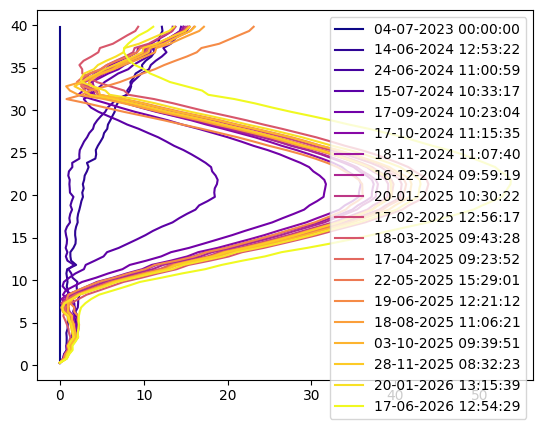

In [142]:
# setup inclino measurements for combiwall mt 76
addmeasurements_inclino = True
addmeasurements_SAAF = False
setupfiles = True # Do not set to true unless you want to reset files
writemetadata = False

pathsuffix = 'BP_mt76'

name = 'Combiwall mt 76'
SAAF_meas_ref = 'None'
inclino_meas_ref = '04-07-2023 00:00:00'
inclino_SAAF_add = 'None'
metadata = {
    'Name': name,
    'Manual inclino reference': inclino_meas_ref,
    'SAAF reference': SAAF_meas_ref,
    'date to add SAAF measurements to former inclino measurements': inclino_SAAF_add
}

rawpath_inclino = f'..//..//Data//Measurements//Raw//inclino_{pathsuffix}.csv'
rawpath_SAAF = f'..//..//Data//Measurements//Raw//SAAF_{pathsuffix}.csv'

if writemetadata:
    with open(f'metadata/{name.replace(" ", "_")}.yaml', 'w') as f:
        yaml.dump(metadata, f)

if setupfiles:
    originpath = '..//..//Data//Measurements//Original//BP_inclino_all.xlsx'
    setup_inclino_file(rawpath_inclino, originpath)

# if setupfiles:
#     originpath = 'measurements\\VP_inclino_LZ_18-01_15-02_26-02_15-03.xlsx'
#     setup_inclino_file(rawpath_SAAF, originpath)



if addmeasurements_inclino:
    # add inclino measurements for combiwall mt 76
    measpath = None
    outpath = f'..//..//Data//Measurements//Inclino_{pathsuffix}.csv' ## change to desired path
    # add_raw_inclino_measurements(measpath, rawpath_inclino) ### adds raw inclino measurements to file (not neccessary))
    reference_inclino_measurements(rawpath_inclino, outpath, inclino_meas_ref, type='vector')


# add SAAF measurements for combiwall mt 76

if addmeasurements_SAAF:
    rawpath_SAAF = f'..//..//Data//Measurements//Raw//SAAF_{pathsuffix}.csv'

    measpath = '..//..//Data//Measurements//Original//VP_inclino_LZ_18-01_15-02_26-02_15-03.xlsx'
    outpath = f'calculations/interm_SAAF/{pathsuffix}.csv'
    add_raw_inclino_measurements(measpath, rawpath_SAAF)
    reference_inclino_measurements(rawpath_SAAF, outpath, SAAF_meas_ref, type='X')

    formerpath = 'calculations/interm_inclino/BP_mt76.csv'
    latterpath = 'calculations/interm_SAAF/BP_mt76.csv'
    outpath = 'calculations/interm_SAAF/BP_mt76_added.csv'
    ref_date = inclino_SAAF_add
    add_to_former(formerpath, latterpath, outpath, ref_date)

    combine_inclino_measurements(f'calculations/interm_inclino/{pathsuffix}.csv', 
                                 f'calculations/interm_SAAF/{pathsuffix}_added.csv', 
                                 f'..//..//Data//Measurements//Inclino_{pathsuffix}.csv')

df = pd.read_csv(f'..//..//Data//Measurements//Inclino_{pathsuffix}.csv', index_col=0, parse_dates=True)

colors = plt.cm.plasma(np.linspace(0, 1, len(df.columns)))
for i, col in enumerate(df.columns):
    plt.plot(df[col], df.index, label=col, color=colors[i])
plt.legend()


# Vibropiles

C:\Users\max\AppData\Local\Temp\ipykernel_26560\4244139141.py:36: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(f'..//..//Data//Measurements//inclino_{pathsuffix}.csv', index_col=0, parse_dates=True)


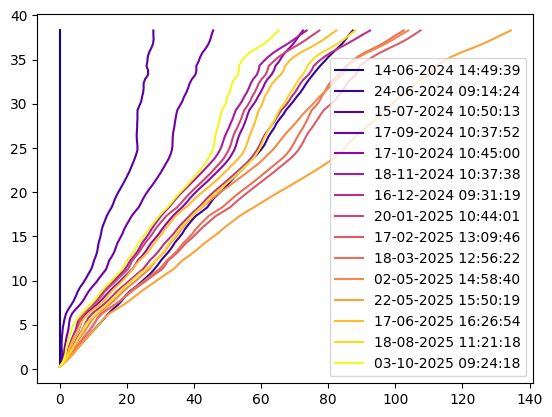

In [143]:
# setup inclino measurements for vibropiles 
addmeasurements_inclino = True
# addmeasurements_SAAF = False
setupfiles = True# Do not set to true unless you want to reset files
writemetadata = False
pathsuffix = 'VP_w_mt76'

name = 'Vibropiles waterside mt 76'
SAAF_meas_ref = '18-01-2026 09:30:00'
inclino_meas_ref = '14-06-2024 14:49:39'
inclino_SAAF_add = '03-10-2025 09:24:18'
metadata = {
    'Name': name,
    'Manual inclino reference': inclino_meas_ref,
    'SAAF reference': SAAF_meas_ref,
    'date to add SAAF measurements to former inclino measurements': inclino_SAAF_add
}

rawpath_inclino = f'..//..//Data/Measurements/Raw/inclino_{pathsuffix}.csv'
originpath_inclino = '..//..//Data/Measurements//Original//VP_inclino_WZ.xlsx'

if writemetadata:
    with open(f'metadata/{name.replace(" ", "_")}.yaml', 'w') as f:
        yaml.dump(metadata, f)

if setupfiles:
    # rawpath_inclino = f'..//..//Data//Measurements//Raw//inclino_{pathsuffix}.csv'
    setup_inclino_file(rawpath_inclino, originpath_inclino)

if addmeasurements_inclino:
    # add inclino measurements for vibropiles waterside
    measpath = originpath_inclino
    outpath = f'..//..//Data//Measurements//inclino_{pathsuffix}.csv'
    add_raw_inclino_measurements(measpath, rawpath_inclino)
    reference_inclino_measurements(rawpath_inclino, outpath, inclino_meas_ref, type='vector')
df = pd.read_csv(f'..//..//Data//Measurements//inclino_{pathsuffix}.csv', index_col=0, parse_dates=True)

colors = plt.cm.plasma(np.linspace(0, 1, len(df.columns)))
for i, col in enumerate(df.columns):
    plt.plot(df[col], df.index, label=col, color=colors[i])
plt.legend()
